# 04. Exploratory Inspection & Data Foundation: Raw Heart Disease Dataset

**Disease**: Heart Disease (Coronary Artery Disease)  
**Phase**: Phase 0 — Disease-Specific Setup, Dataset Understanding, Provenance and Data Foundation  
**Dataset**: UCI Heart Disease (Cleveland Clinic Foundation)  
**File**: `datasets/raw/heart/processed.cleveland.data`  

---

### Constraints & Scope
- **Immutable Source**: The raw dataset file `datasets/raw/heart/processed.cleveland.data` is treated as strictly read-only and will never be modified.
- **Exploratory & Analytical Scope**: This notebook performs dataset provenance recording, raw schema verification, missing value identification, duplicate detection, target distribution analysis, feature semantics documentation, feature-type classification, numerical and categorical analysis, data quality auditing, and preliminary preprocessing architecture design.
- **Strict Bounds**: 
  - NO machine learning models are trained.
  - NO classification thresholds are selected.
  - NO probability calibration is performed.
  - NO SHAP explainability artifacts are generated.
  - NO synthetic or mock data is introduced.
  - Existing Liver Disease implementations remain completely untouched.


In [1]:
import os
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Dataset configuration
RAW_DATA_PATH = os.path.join('datasets', 'raw', 'heart', 'processed.cleveland.data')

# Standard 14-column clinical schema for Cleveland Heart Disease dataset
COLUMNS = [
    'age',       # Age in years
    'sex',       # Biological sex (1=male, 0=female)
    'cp',        # Chest pain type (1, 2, 3, 4)
    'trestbps',  # Resting blood pressure (mm Hg)
    'chol',      # Serum cholesterol (mg/dl)
    'fbs',       # Fasting blood sugar > 120 mg/dl (1=true, 0=false)
    'restecg',   # Resting electrocardiographic results (0, 1, 2)
    'thalach',   # Maximum heart rate achieved (bpm)
    'exang',     # Exercise induced angina (1=yes, 0=no)
    'oldpeak',   # ST depression induced by exercise relative to rest
    'slope',     # Slope of peak exercise ST segment (1, 2, 3)
    'ca',        # Number of major vessels (0-3) colored by fluoroscopy
    'thal',      # Thallium scintigraphy (3=normal, 6=fixed defect, 7=reversible defect)
    'num'        # Diagnosis of heart disease (angiographic disease status, 0-4)
]

print(f"Environment initialized. Target dataset path: {RAW_DATA_PATH}")


Environment initialized. Target dataset path: datasets\raw\heart\processed.cleveland.data


## 1. Dataset Provenance & Source Documentation

### Provenance Metadata
- **Dataset Name**: Heart Disease Database (Cleveland Clinic Foundation)
- **Source**: UCI Machine Learning Repository
- **Creators / Principal Investigators**:
  1. Robert Detrano, M.D., Ph.D. — V.A. Medical Center, Long Beach and Cleveland Clinic Foundation
  2. Andras Janosi, M.D. — Hungarian Institute of Cardiology, Budapest
  3. William Steinbrunn, M.D. — University Hospital, Zurich, Switzerland
  4. Matthias Pfisterer, M.D. — University Hospital, Basel, Switzerland
- **Donor**: David W. Aha
- **Original Filename**: `processed.cleveland.data`
- **Local Repository Path**: `datasets/raw/heart/processed.cleveland.data`
- **Total Records in File**: 303 patient observations
- **Total Attributes in File**: 14 (13 clinical/demographic predictive attributes + 1 angiographic status target)
- **Target Variable**: `num` (0: absence of angiographic CAD; 1–4: presence of CAD with increasing vessel involvement)
- **Missing Value Sentinel**: String literal `'?'`
- **Known Dataset Limitations**:
  1. *Sample Size*: 303 observations is a modest sample size, requiring parsimonious modeling and careful cross-validation to avoid overfitting.
  2. *Demographic Skew*: 67.99% male (206) vs 32.01% female (97), reflecting late-1980s referral patterns for coronary angiography.
  3. *Single-Center Cohort*: Data originated from the Cleveland Clinic, which may reflect specific referral and demographic patterns not universally representative of broader global populations.
  4. *Invasive/Specialized Predictors*: Features such as `ca` (fluoroscopy) and `thal` (thallium nuclear stress test) require specialized hospital testing and contain missing entries.


In [2]:
def compute_checksums(file_path):
    """Compute SHA-256 and MD5 checksums for verifying raw file immutability."""
    with open(file_path, 'rb') as f:
        bytes_data = f.read()
    sha256_hash = hashlib.sha256(bytes_data).hexdigest()
    md5_hash = hashlib.md5(bytes_data).hexdigest()
    return len(bytes_data), md5_hash, sha256_hash

initial_bytes, initial_md5, initial_sha256 = compute_checksums(RAW_DATA_PATH)

print("=== RAW DATASET INTEGRITY CHECK (PRE-ANALYSIS) ===")
print(f"File Path    : {RAW_DATA_PATH}")
print(f"File Size    : {initial_bytes} bytes")
print(f"MD5 Hash     : {initial_md5}")
print(f"SHA-256 Hash : {initial_sha256}")


=== RAW DATASET INTEGRITY CHECK (PRE-ANALYSIS) ===
File Path    : datasets\raw\heart\processed.cleveland.data
File Size    : 18461 bytes
MD5 Hash     : 2d91a8ff69cfd9616aa47b59d6f843db
SHA-256 Hash : a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8


## 2. Raw Schema Analysis & Data Ingestion

The raw Cleveland file `processed.cleveland.data` is a headerless comma-separated text file. We ingest it with `header=None` and assign the canonical 14 attribute names.


In [3]:
df_raw = pd.read_csv(RAW_DATA_PATH, header=None, names=COLUMNS)

print("=== DATASET DIMENSIONS ===")
print(f"Total Rows (Observations) : {df_raw.shape[0]}")
print(f"Total Columns (Attributes): {df_raw.shape[1]}")

print("\n=== ASSIGNED SCHEMA & INFERRED PANDAS DTYPES ===")
dtypes_df = pd.DataFrame({
    'Column': df_raw.columns,
    'Inferred Dtype': df_raw.dtypes.values,
    'Non-Null Count': df_raw.count().values,
    'Sample Value (Row 0)': df_raw.iloc[0].values
})
print(dtypes_df.to_string(index=False))

print("\n=== FIRST 10 RECORDS ===")
display(df_raw.head(10))

print("\n=== LAST 5 RECORDS ===")
display(df_raw.tail(5))


=== DATASET DIMENSIONS ===
Total Rows (Observations) : 303
Total Columns (Attributes): 14

=== ASSIGNED SCHEMA & INFERRED PANDAS DTYPES ===
  Column Inferred Dtype  Non-Null Count Sample Value (Row 0)
     age        float64             303                 63.0
     sex        float64             303                  1.0
      cp        float64             303                  1.0
trestbps        float64             303                145.0
    chol        float64             303                233.0
     fbs        float64             303                  1.0
 restecg        float64             303                  2.0
 thalach        float64             303                150.0
   exang        float64             303                  0.0
 oldpeak        float64             303                  2.3
   slope        float64             303                  3.0
      ca         object             303                  0.0
    thal         object             303                  6.0
     n

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1



=== LAST 5 RECORDS ===


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,?,3.0,0


## 3. Missing Value Analysis

In standard CSV ingestion, missing values encoded as alphanumeric sentinels (such as `'?'`) are not detected by pandas default null checks (`isna()`), and cause numeric columns to be downcast to generic `object` dtype.
Here we systematically audit both standard nulls and sentinel values.


In [4]:
print("=== STANDARD NULL VALUES (df.isna()) ===")
standard_nulls = df_raw.isna().sum()
print(standard_nulls)

print("\n=== SENTINEL '?' VALUE AUDIT ===")
sentinel_counts = {}
for col in df_raw.columns:
    count_q = (df_raw[col] == '?').sum()
    sentinel_counts[col] = count_q

sentinel_df = pd.DataFrame({
    'Feature': list(sentinel_counts.keys()),
    'Standard NaNs': standard_nulls.values,
    "Sentinel '?' Count": list(sentinel_counts.values()),
    "Missing Percentage (%)": [round(c / len(df_raw) * 100, 2) for c in sentinel_counts.values()]
})
print(sentinel_df[sentinel_df["Sentinel '?' Count"] > 0].to_string(index=False))

# Identify specific rows with missing values
rows_with_sentinel = df_raw[(df_raw['ca'] == '?') | (df_raw['thal'] == '?')]
print(f"\nTotal rows containing sentinel '?' values: {len(rows_with_sentinel)} ({len(rows_with_sentinel)/len(df_raw)*100:.2f}%)")
print("Row indices:", rows_with_sentinel.index.tolist())
print("\nDetails of affected observations:")
display(rows_with_sentinel[['age', 'sex', 'cp', 'trestbps', 'chol', 'ca', 'thal', 'num']])


=== STANDARD NULL VALUES (df.isna()) ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

=== SENTINEL '?' VALUE AUDIT ===
Feature  Standard NaNs  Sentinel '?' Count  Missing Percentage (%)
     ca              0                   4                    1.32
   thal              0                   2                    0.66

Total rows containing sentinel '?' values: 6 (1.98%)
Row indices: [87, 166, 192, 266, 287, 302]

Details of affected observations:


,age,sex,cp,trestbps,chol,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,?,0
166,52.0,1.0,3.0,138.0,223.0,?,3.0,0
192,43.0,1.0,4.0,132.0,247.0,?,7.0,1
266,52.0,1.0,4.0,128.0,204.0,0.0,?,2
287,58.0,1.0,2.0,125.0,220.0,?,7.0,0
302,38.0,1.0,3.0,138.0,175.0,?,3.0,0


## 4. Duplicate Observation Analysis

We check for exact duplicate rows across all 14 attributes to prevent replication bias or train-test fold leakage.


In [5]:
duplicate_mask = df_raw.duplicated()
num_duplicates = duplicate_mask.sum()

print("=== DUPLICATE OBSERVATION CHECK ===")
print(f"Number of exact duplicate rows: {num_duplicates}")
print(f"Duplicate percentage          : {num_duplicates / len(df_raw) * 100:.2f}%")

if num_duplicates > 0:
    print("Duplicate rows detected:")
    display(df_raw[duplicate_mask])
else:
    print("Finding: Every row in the Cleveland dataset represents an entirely unique feature vector.")


=== DUPLICATE OBSERVATION CHECK ===
Number of exact duplicate rows: 0
Duplicate percentage          : 0.00%
Finding: Every row in the Cleveland dataset represents an entirely unique feature vector.


## 5. Target Variable (`num`) Analysis

### Clinical Meaning of `num`
The target attribute `num` represents the angiographic disease status of the patient determined via coronary angiography:
- **`0`**: Absence of significant coronary artery disease (< 50% diameter stenosis in all major coronary vessels).
- **`1`**: Stage 1 coronary artery disease (presence of significant stenosis, >= 50% diameter narrowing).
- **`2`**: Stage 2 coronary artery disease.
- **`3`**: Stage 3 coronary artery disease.
- **`4`**: Stage 4 coronary artery disease.

### Separation of Raw Target vs. Planned Model Target
- **Raw Target**: Kept strictly unmodified in `datasets/raw/heart/processed.cleveland.data` with values 0 to 4.
- **Planned Screening Target**: For clinical screening purposes, the platform plans to formulate a binary detection task:
  - `0` (Negative / Absence of CAD): `num == 0`
  - `1` (Positive / Presence of CAD): `num >= 1`
- **Important**: This binary formulation is documented here as an *exploratory planning decision*, NOT as an already trained or production-validated classifier.


=== RAW MULTI-STAGE TARGET DISTRIBUTION ===


 Raw num Value          Clinical Stage  Count  Percentage (%)
             0 Absence (<50% stenosis)    164           54.13
             1             Stage 1 CAD     55           18.15
             2             Stage 2 CAD     36           11.88
             3             Stage 3 CAD     35           11.55
             4             Stage 4 CAD     13            4.29

=== EXPLORATORY BINARY SCREENING FORMULATION ===
 Binary Class              Screening Label  Count  Percentage (%)
            0    Negative (Absence, num=0)    164           54.13
            1 Positive (Presence, num 1-4)    139           45.87

Class balance ratio (Negative : Positive): 1.18 : 1
Positive prevalence in cohort            : 45.87%


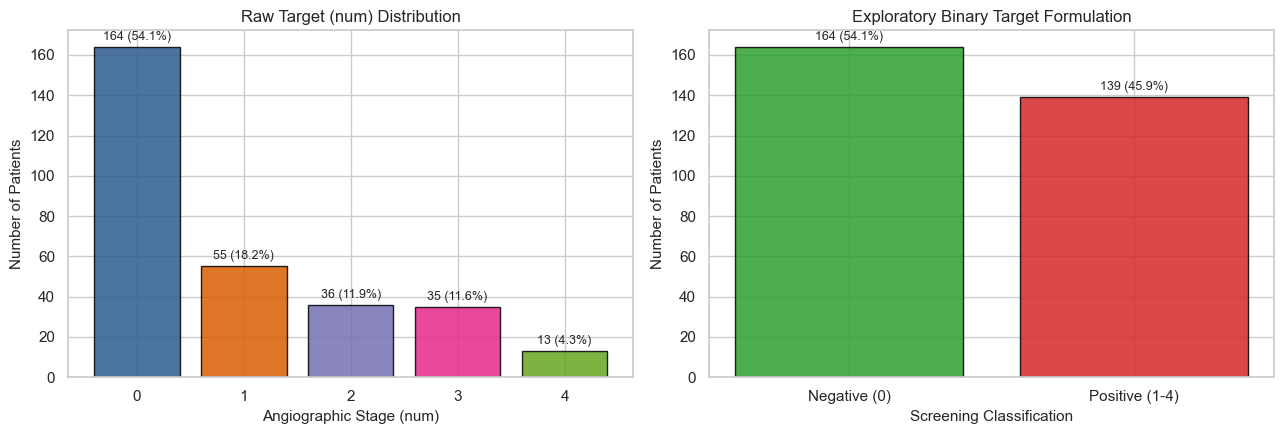

In [6]:
target_counts = df_raw['num'].value_counts().sort_index()
target_pct = (df_raw['num'].value_counts(normalize=True).sort_index() * 100).round(2)

target_summary = pd.DataFrame({
    'Raw num Value': target_counts.index,
    'Clinical Stage': ['Absence (<50% stenosis)', 'Stage 1 CAD', 'Stage 2 CAD', 'Stage 3 CAD', 'Stage 4 CAD'],
    'Count': target_counts.values,
    'Percentage (%)': target_pct.values
})
print("=== RAW MULTI-STAGE TARGET DISTRIBUTION ===")
print(target_summary.to_string(index=False))

# Exploratory Binary Mapping
binary_target = (df_raw['num'] > 0).astype(int)
bin_counts = binary_target.value_counts().sort_index()
bin_pct = (binary_target.value_counts(normalize=True).sort_index() * 100).round(2)

binary_summary = pd.DataFrame({
    'Binary Class': [0, 1],
    'Screening Label': ['Negative (Absence, num=0)', 'Positive (Presence, num 1-4)'],
    'Count': bin_counts.values,
    'Percentage (%)': bin_pct.values
})
print("\n=== EXPLORATORY BINARY SCREENING FORMULATION ===")
print(binary_summary.to_string(index=False))

# Ratio calculation
neg_count = bin_counts[0]
pos_count = bin_counts[1]
print(f"\nClass balance ratio (Negative : Positive): {neg_count / pos_count:.2f} : 1")
print(f"Positive prevalence in cohort            : {pos_count / len(df_raw) * 100:.2f}%")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Raw distribution
bars1 = axes[0].bar(target_counts.index, target_counts.values, color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a', '#66a61e'], edgecolor='black', alpha=0.85)
axes[0].set_title('Raw Target (num) Distribution')
axes[0].set_xlabel('Angiographic Stage (num)')
axes[0].set_ylabel('Number of Patients')
axes[0].set_xticks([0, 1, 2, 3, 4])
for bar in bars1:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, y + 2, f'{int(y)} ({y/303*100:.1f}%)', ha='center', va='bottom', fontsize=9)

# Binary distribution
bars2 = axes[1].bar(['Negative (0)', 'Positive (1-4)'], bin_counts.values, color=['#2ca02c', '#d62728'], edgecolor='black', alpha=0.85)
axes[1].set_title('Exploratory Binary Target Formulation')
axes[1].set_xlabel('Screening Classification')
axes[1].set_ylabel('Number of Patients')
for bar in bars2:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, y + 2, f'{int(y)} ({y/303*100:.1f}%)', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


## 6. Feature Semantics & Clinical Data Dictionary

The Cleveland Heart Disease dataset contains 14 clinical, physiological, and diagnostic variables. Below is the complete feature dictionary:

| Feature Name | Clinical Meaning | Raw Representation | Data Type | Semantic Type | Missingness Behavior | Preprocessing Consideration |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **`age`** | Age of the patient in years | Continuous integer encoded as `float64` (29.0–77.0) | `float64` | Continuous Numerical | None (0 missing) | Standard scaling required for linear models. |
| **`sex`** | Biological sex of the patient | Binary indicator: `1.0` = Male, `0.0` = Female | `float64` | Binary Categorical | None (0 missing) | Keep as binary indicator `{0, 1}`. Note 68% male cohort skew. |
| **`cp`** | Chest pain type experienced | Coded integer: `1.0` = Typical Angina, `2.0` = Atypical Angina, `3.0` = Non-anginal Pain, `4.0` = Asymptomatic | `float64` | Nominal Categorical (4 levels) | None (0 missing) | Must NOT be treated as ordinal. Requires One-Hot Encoding (`drop='first'` or full) to avoid false distance assumption. |
| **`trestbps`** | Resting blood pressure on admission to hospital | Blood pressure in mm Hg (94.0–200.0) | `float64` | Continuous Numerical | None (0 missing) | Standard scaling required for linear models. Robust to modest elevation. |
| **`chol`** | Serum cholesterol level | Measurement in mg/dl (126.0–564.0) | `float64` | Continuous Numerical | None (0 missing) | Right-skewed distribution with max of 564 mg/dl. RobustScaler or standard scaler to be evaluated. |
| **`fbs`** | Fasting blood sugar > 120 mg/dl | Binary indicator: `1.0` = True (>120 mg/dl), `0.0` = False (<=120 mg/dl) | `float64` | Binary Categorical | None (0 missing) | Keep as binary indicator `{0, 1}`. Reflects diabetic/prediabetic hyperglycemia marker. |
| **`restecg`** | Resting electrocardiographic results | Coded integer: `0.0` = Normal, `1.0` = ST-T wave abnormality, `2.0` = Left ventricular hypertrophy (Estes' criteria) | `float64` | Nominal Categorical (3 levels) | None (0 missing) | Nominal categorical. Category `1.0` has only 4 samples (1.32%); requires careful handling during one-hot encoding. |
| **`thalach`** | Maximum heart rate achieved during exercise stress test | Beats per minute (bpm) (71.0–202.0) | `float64` | Continuous Numerical | None (0 missing) | Strong physiological predictor. Standard scaling required for linear models. |
| **`exang`** | Exercise-induced angina | Binary indicator: `1.0` = Yes, `0.0` = No | `float64` | Binary Categorical | None (0 missing) | Keep as binary indicator `{0, 1}`. Highly specific clinical marker for ischemic CAD. |
| **`oldpeak`** | ST depression induced by exercise relative to rest | Electrocardiographic depression in mm (0.0–6.2) | `float64` | Continuous Numerical | None (0 missing) | Right-skewed continuous variable with zero-inflation (nearly 33% at 0.0 mm). Standard/robust scaling. |
| **`slope`** | Slope of the peak exercise ST segment | Coded integer: `1.0` = Upsloping, `2.0` = Flat, `3.0` = Downsloping | `float64` | Ordinal / Categorical (3 levels) | None (0 missing) | Clinically ordered severity (upsloping is less severe, flat/downsloping indicates progressive ischemia). Can be one-hot encoded or ordinal encoded. |
| **`ca`** | Number of major coronary vessels colored by fluoroscopy | Discrete count integer: `0.0`, `1.0`, `2.0`, `3.0` | `object` (due to `'?'`) | Discrete Count Numerical | 4 missing records (`'?'`, 1.32%) | Needs median or mode imputation fitted strictly on training folds. Can be modeled as discrete numeric or ordinal. |
| **`thal`** | Thallium scintigraphy (cardiac nuclear stress test) | Coded integer: `3.0` = Normal, `6.0` = Fixed defect, `7.0` = Reversible defect | `object` (due to `'?'`) | Nominal Categorical (3 levels) | 2 missing records (`'?'`, 0.66%) | Non-consecutive integers (3, 6, 7). Needs mode imputation on train set followed by One-Hot Encoding. |
| **`num`** | Diagnosis of coronary heart disease | Coded integer: `0` (absence) to `1, 2, 3, 4` (stages of stenosis) | `int64` | Target Variable (Multi-stage / Binary) | None (0 missing) | Transformed to binary `0` vs `1-4` for screening. Kept untouched in raw storage. |


## 7. Feature-Type Classification & Rationale

A common pitfall in machine learning on medical tabular datasets is treating every numeric column as a continuous variable. The Cleveland dataset encodes categorical and ordinal states as floating-point numbers (`float64`) in the raw file.

### Systematic Classification
1. **Continuous Numerical Features (5)**:
   - `age`: Physical biological age in years.
   - `trestbps`: Continuous physical pressure in mm Hg.
   - `chol`: Continuous biochemical serum concentration in mg/dl.
   - `thalach`: Continuous physical heart rate in bpm.
   - `oldpeak`: Continuous electrocardiographic electrical potential depression in mm.
   - *Rationale*: These variables possess true continuous scales where Euclidean distances, differences, and ratios are mathematically meaningful.

2. **Discrete Count Numerical Features (1)**:
   - `ca`: Number of major blood vessels (0, 1, 2, 3) colored during fluoroscopy.
   - *Rationale*: Non-negative discrete count with an inherent numerical ordering and natural zero.

3. **Binary Categorical Features (3)**:
   - `sex`: Biological sex (0 = female, 1 = male).
   - `fbs`: Fasting blood sugar threshold indicator (0 = <=120 mg/dl, 1 = >120 mg/dl).
   - `exang`: Exercise-induced angina indicator (0 = no, 1 = yes).
   - *Rationale*: Two mutually exclusive states representing presence or absence.

4. **Nominal Categorical Features (3)**:
   - `cp`: 4 distinct chest pain presentations (1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic). Coding numbers do not reflect monotonic disease severity.
   - `restecg`: 3 distinct electrocardiographic findings (0: normal, 1: ST-T wave changes, 2: LV hypertrophy).
   - `thal`: 3 distinct myocardial perfusion scintigraphy findings (3: normal, 6: fixed defect, 7: reversible defect). Non-continuous legacy code numbers.
   - *Rationale*: No intrinsic mathematical ordering; must be one-hot encoded to prevent imposing artificial distance metrics.

5. **Ordinal Categorical Features (1)**:
   - `slope`: 3 exercise ST-segment slope trajectories (1: upsloping, 2: flat, 3: downsloping).
   - *Rationale*: Clinically established physiological hierarchy of ischemia severity (upsloping is benign/normal; flat is equivocal/ischemic; downsloping is strongly pathological).


## 8. Numerical Features Statistical Analysis

We construct a temporary numeric view exclusively for reporting statistical parameters without altering the underlying raw dataset.


=== DESCRIPTIVE STATISTICS FOR NUMERICAL & COUNT FEATURES ===
          count    mean    std    min    25%  median    75%    max   iqr  skewness
age       303.0   54.44   9.04   29.0   48.0    56.0   61.0   77.0  13.0     -0.21
trestbps  303.0  131.69  17.60   94.0  120.0   130.0  140.0  200.0  20.0      0.71
chol      303.0  246.69  51.78  126.0  211.0   241.0  275.0  564.0  64.0      1.14
thalach   303.0  149.61  22.88   71.0  133.5   153.0  166.0  202.0  32.5     -0.54
oldpeak   303.0    1.04   1.16    0.0    0.0     0.8    1.6    6.2   1.6      1.27
ca        299.0    0.67   0.94    0.0    0.0     0.0    1.0    3.0   1.0      1.19

=== EXTREME VALUE INSPECTION ===
Top 5 highest cholesterol values (chol): [564.0, 417.0, 409.0, 407.0, 394.0]
Top 5 highest resting blood pressure (trestbps): [200.0, 192.0, 180.0, 180.0, 180.0]
Top 5 highest ST depression (oldpeak): [6.2, 5.6, 4.4, 4.2, 4.2]
Lowest 5 maximum heart rates (thalach): [71.0, 88.0, 90.0, 95.0, 96.0]


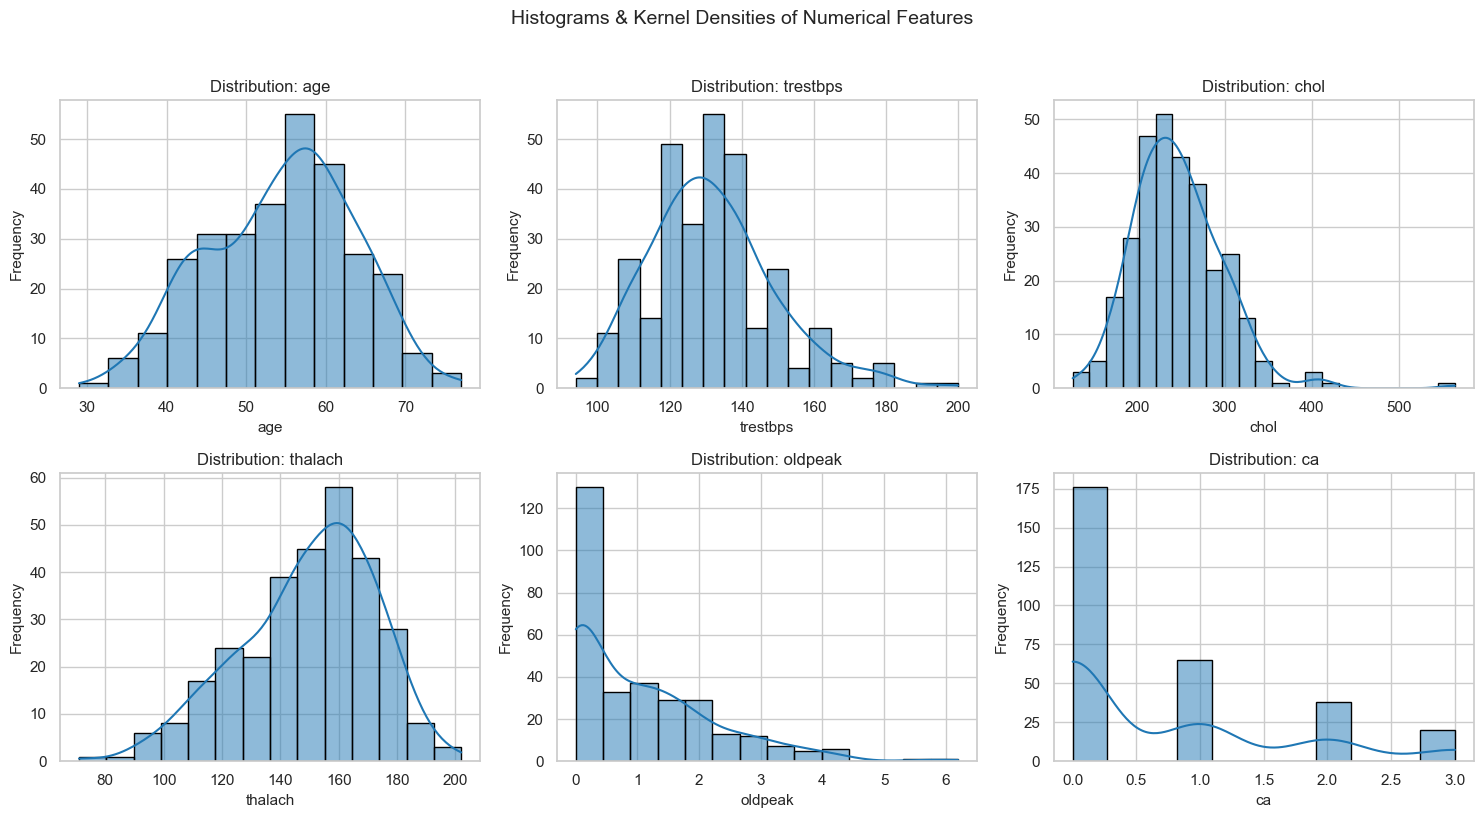

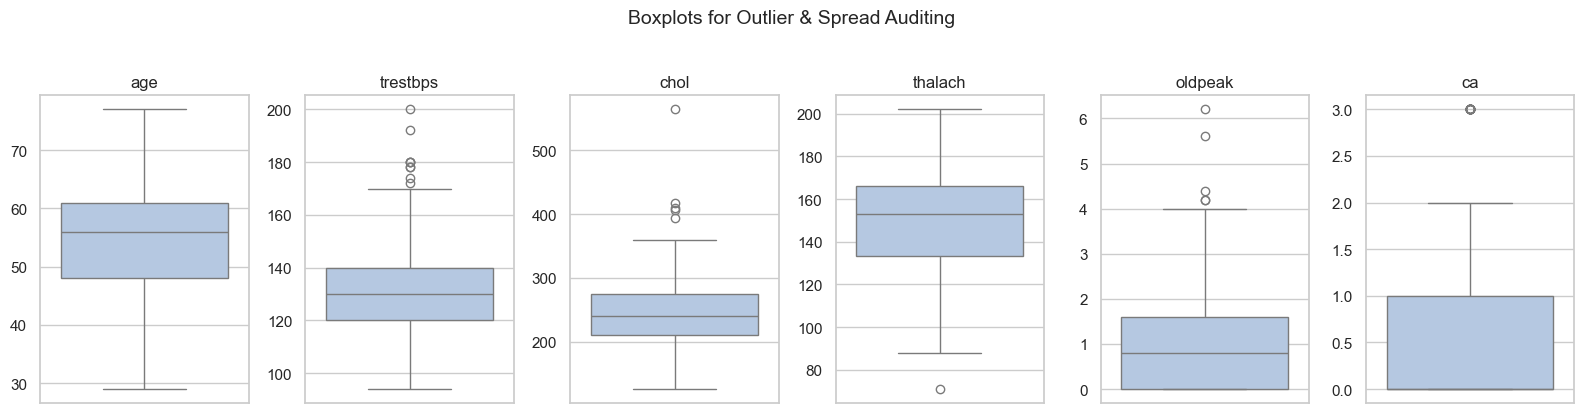

In [7]:
# Temporary numeric view for descriptive reporting
df_num_view = df_raw.copy()
df_num_view['ca'] = pd.to_numeric(df_num_view['ca'].replace('?', np.nan))
df_num_view['thal'] = pd.to_numeric(df_num_view['thal'].replace('?', np.nan))

num_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

desc_stats = df_num_view[num_features].describe().T
desc_stats['median'] = df_num_view[num_features].median()
desc_stats['iqr'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['skewness'] = df_num_view[num_features].skew()

report_cols = ['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'iqr', 'skewness']
print("=== DESCRIPTIVE STATISTICS FOR NUMERICAL & COUNT FEATURES ===")
print(desc_stats[report_cols].round(2).to_string())

# Extreme Value Investigation
print("\n=== EXTREME VALUE INSPECTION ===")
print(f"Top 5 highest cholesterol values (chol): {df_num_view['chol'].nlargest(5).tolist()}")
print(f"Top 5 highest resting blood pressure (trestbps): {df_num_view['trestbps'].nlargest(5).tolist()}")
print(f"Top 5 highest ST depression (oldpeak): {df_num_view['oldpeak'].nlargest(5).tolist()}")
print(f"Lowest 5 maximum heart rates (thalach): {df_num_view['thalach'].nsmallest(5).tolist()}")

# Distribution Plots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, col in enumerate(num_features):
    sns.histplot(df_num_view[col].dropna(), kde=True, ax=axes[idx], color='#1f77b4', edgecolor='black')
    axes[idx].set_title(f'Distribution: {col}')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frequency')

plt.suptitle('Histograms & Kernel Densities of Numerical Features', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Boxplot Outlier Inspection
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for idx, col in enumerate(num_features):
    sns.boxplot(y=df_num_view[col].dropna(), ax=axes[idx], color='#aec7e8')
    axes[idx].set_title(col)
    axes[idx].set_ylabel('')

plt.suptitle('Boxplots for Outlier & Spread Auditing', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()


## 9. Categorical, Binary, and Ordinal Variable Distributions

We examine the frequency and percentage breakdown for all non-continuous clinical features.


=== CATEGORICAL FEATURE DISTRIBUTIONS ===

--- Feature: sex ---
Category Value  Count  Percentage (%)
           0.0     97           32.01
           1.0    206           67.99

--- Feature: cp ---
Category Value  Count  Percentage (%)
           1.0     23            7.59
           2.0     50           16.50
           3.0     86           28.38
           4.0    144           47.52

--- Feature: fbs ---
Category Value  Count  Percentage (%)
           0.0    258           85.15
           1.0     45           14.85

--- Feature: restecg ---
Category Value  Count  Percentage (%)
           0.0    151           49.83
           1.0      4            1.32
           2.0    148           48.84

--- Feature: exang ---
Category Value  Count  Percentage (%)
           0.0    204           67.33
           1.0     99           32.67

--- Feature: slope ---
Category Value  Count  Percentage (%)
           1.0    142           46.86
           2.0    140           46.20
           3.0     21

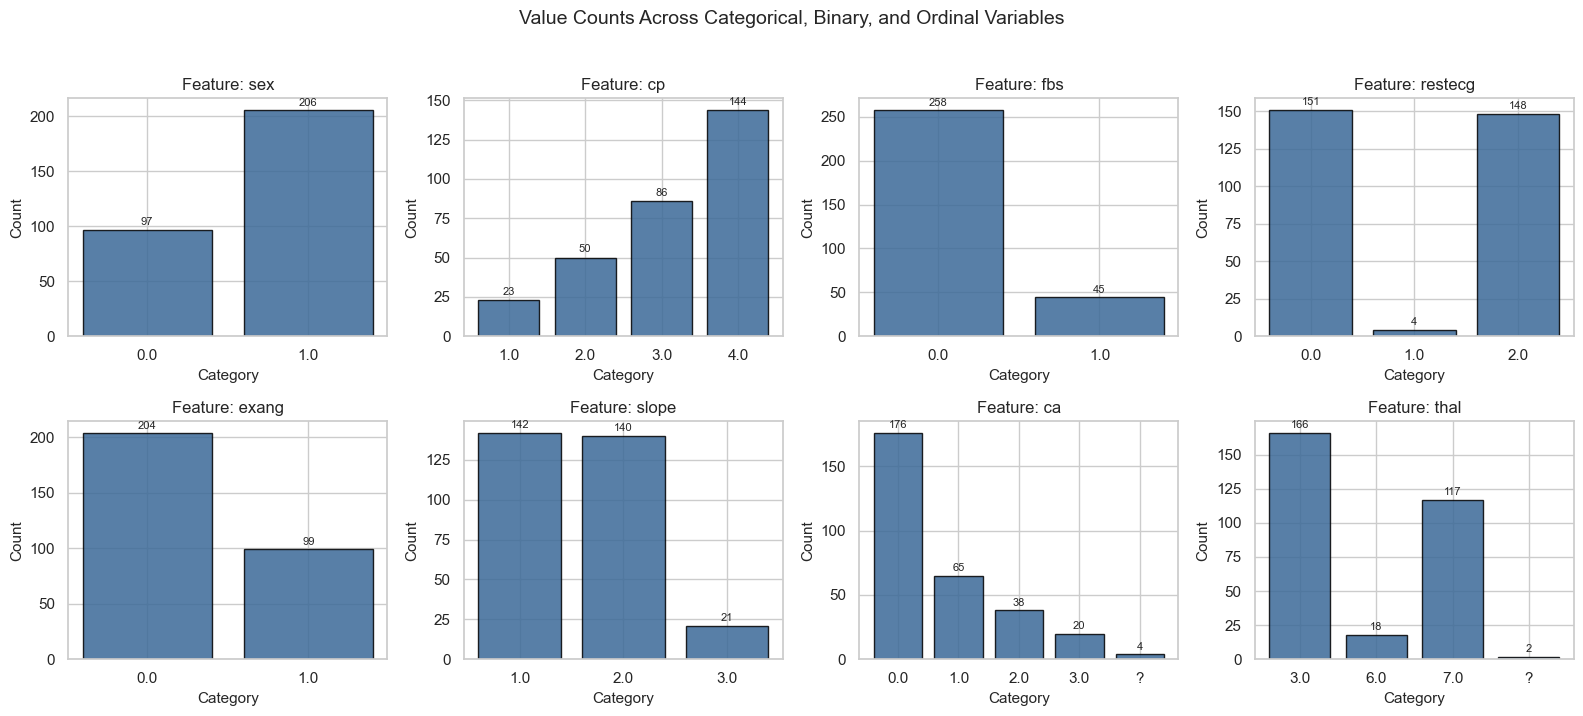

In [8]:
cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

print("=== CATEGORICAL FEATURE DISTRIBUTIONS ===")
for col in cat_features:
    val_counts = df_raw[col].value_counts(dropna=False).sort_index()
    val_pct = (df_raw[col].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2)
    cat_summary = pd.DataFrame({
        'Category Value': val_counts.index.astype(str),
        'Count': val_counts.values,
        'Percentage (%)': val_pct.values
    })
    print(f"\n--- Feature: {col} ---")
    print(cat_summary.to_string(index=False))

# Visualization of Categorical Distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for idx, col in enumerate(cat_features):
    counts = df_raw[col].value_counts().sort_index()
    axes[idx].bar([str(x) for x in counts.index], counts.values, color='#3b6998', edgecolor='black', alpha=0.85)
    axes[idx].set_title(f'Feature: {col}')
    axes[idx].set_xlabel('Category')
    axes[idx].set_ylabel('Count')
    for x_pos, y_val in enumerate(counts.values):
        axes[idx].text(x_pos, y_val + 2, str(y_val), ha='center', va='bottom', fontsize=8)

plt.suptitle('Value Counts Across Categorical, Binary, and Ordinal Variables', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 10. Comprehensive Data Quality Findings

Based on our exhaustive analysis of the raw Cleveland Heart Disease dataset, the following data quality observations are documented:

1. **Absence of Corrupted / Malformed Lines**:
   - The raw file contains exactly 303 lines. Every line contains exactly 14 comma-delimited tokens. No empty lines or parsing anomalies exist.
2. **Sentinel String Characters as Missing Indicators**:
   - Two features contain `'?'` characters indicating missing test results:
     - `ca`: 4 missing observations (1.32% of cohort; rows 166, 192, 287, 302).
     - `thal`: 2 missing observations (0.66% of cohort; rows 87, 266).
   - In total, exactly 6 patient records (1.98%) contain missing values.
   - Standard `df.isna()` reports 0 nulls; imputation pipelines must explicitly replace `'?'` with `NaN` before imputation.
3. **Data Type Representation**:
   - Because of `'?'`, `ca` and `thal` are inferred by pandas as `object` dtype.
   - Categorical and binary features (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`) are stored as `float64` numbers.
4. **Zero Duplicate Rows**:
   - No duplicate patient observations exist in the dataset (0 duplicates / 0.0%).
5. **Class Balance**:
   - Raw 5-class target: Stage 4 has only 13 observations (4.29%), making fine-grained multi-class learning statistically fragile.
   - Exploratory binary formulation: 164 negative (54.13%) vs. 139 positive (45.87%), yielding a healthy balance ratio of 1.18 : 1.
6. **Rare Categories**:
   - In `restecg`, category `1.0` (ST-T wave abnormality) appears in only 4 observations (1.32%).
   - During cross-validation splitting, care must be taken that fold splits or one-hot encoders do not encounter unseen categories or zero-variance columns.
7. **Biological Extreme Values**:
   - `chol` exhibits a maximum value of 564.0 mg/dl (patient index 48). While clinically extreme (severe hypercholesterolemia), this is physiologically possible and should not be discarded without empirical evaluation.
   - `trestbps` reaches 200 mm Hg (severe hypertensive crisis), which is clinically valid.


## 11. Preliminary Preprocessing Design Plan

*Note: This section outlines the architectural blueprint for future Heart Disease preprocessing (Phase 1 / Phase 5). NO models are trained in this phase.*

```
Raw Data Ingestion (datasets/raw/heart/processed.cleveland.data)
                    │
                    ▼
          Convert '?' to NaN
                    │
                    ▼
     Stratified Train / Test Split (e.g. 80/20, fixed seed)
                    │
       ┌────────────┴────────────┐
       ▼                         ▼
   Train Set                 Test Set (Hold-out, Isolated)
       │                         │
       ▼                         │
   Fit Pipeline (Transformer)    │
   - Imputation: Median/Mode     │
   - Categorical: One-Hot        │
   - Numerical: Standard/Robust  │
       │                         │
       ▼                         ▼
   Transform Train           Transform Test
       │                         │
       ▼                         ▼
   Model Training            Unbiased Evaluation
   (LR, RF, XGBoost)
```

### 1. Missing-Value Handling Strategy
- Sentinel `'?'` strings will be mapped to standard `np.nan` upon pipeline ingestion.
- Given the low missingness rate (4 in `ca`, 2 in `thal`, total < 2%), simple median/mode imputation or iterative imputation fitted strictly on training folds will preserve the entire 303-observation cohort without data leakage.

### 2. Categorical Encoding Architecture
- **Nominal Features** (`cp`, `restecg`, `thal`): Must be encoded using `OneHotEncoder(handle_unknown='ignore', drop='first')` to prevent artificial numerical distances.
- **Binary Features** (`sex`, `fbs`, `exang`): Retained as binary indicators `{0, 1}`.
- **Ordinal Features** (`slope`): Evaluated either as ordinal integers (1, 2, 3) or via one-hot encoding during model benchmarking.

### 3. Numerical Feature Handling & Outlier Policy
- Continuous features (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) will be evaluated under `StandardScaler` (zero mean, unit variance) and `RobustScaler` (median-centered, IQR-scaled).
- Extreme biological observations (e.g., cholesterol = 564 mg/dl) will NOT be trimmed or deleted, as extreme physiological values frequently indicate true cardiovascular risk in clinical populations.

### 4. Algorithm-Specific Requirements
- **Logistic Regression**: Strictly requires numerical feature scaling and one-hot encoding of nominal variables to ensure stable gradient convergence and interpretable coefficients.
- **Random Forest**: Invariant to monotonic feature scaling, capable of handling mixed scales, and robust to outliers, but requires proper categorical encoding.
- **XGBoost**: Tree-based gradient boosting, invariant to feature scaling, handles sparsity from one-hot encodings effectively.

### 5. Binary Target Construction
- Mapping: `y = (df['num'] > 0).astype(int)`.
- Absence (0): 54.13% | Presence (1): 45.87%.
- Raw target column in `datasets/raw/heart/` remains strictly immutable.

### 6. Validation Splitting & Leakage Prevention Protocol
- **Validation Scheme**: Repeated Stratified K-Fold Cross-Validation (e.g., 5-fold, 10 repeats) to preserve the ~54% / 46% balance across all folds.
- **Hold-out Split**: An isolated 20% stratified hold-out test set will be set aside prior to any transformation fitting.
- **Strict Fit-on-Train**: All pipeline transformations (`SimpleImputer`, `OneHotEncoder`, `StandardScaler`) must call `.fit()` exclusively on the training split/folds and `.transform()` on evaluation data.
- **Zero Target Leakage**: Target values will never inform feature transformations.


## 12. Post-Analysis Raw Dataset Integrity Verification

We re-compute the cryptographic checksums of `datasets/raw/heart/processed.cleveland.data` to prove that the raw source file remained completely unmodified throughout the analysis.


In [9]:
final_bytes, final_md5, final_sha256 = compute_checksums(RAW_DATA_PATH)

print("=== RAW DATASET INTEGRITY VERIFICATION (POST-ANALYSIS) ===")
print(f"File Path        : {RAW_DATA_PATH}")
print(f"Pre-Analysis MD5 : {initial_md5}")
print(f"Post-Analysis MD5: {final_md5}")
print(f"MD5 Unchanged    : {initial_md5 == final_md5}")
print(f"\nPre-Analysis SHA-256 : {initial_sha256}")
print(f"Post-Analysis SHA-256: {final_sha256}")
print(f"SHA-256 Unchanged    : {initial_sha256 == final_sha256}")

assert initial_md5 == final_md5, "CRITICAL ERROR: Raw dataset MD5 checksum has changed!"
assert initial_sha256 == final_sha256, "CRITICAL ERROR: Raw dataset SHA-256 checksum has changed!"
print("\nVERIFICATION PASSED: The raw Heart Disease dataset is 100% immutable and unchanged.")


=== RAW DATASET INTEGRITY VERIFICATION (POST-ANALYSIS) ===
File Path        : datasets\raw\heart\processed.cleveland.data
Pre-Analysis MD5 : 2d91a8ff69cfd9616aa47b59d6f843db
Post-Analysis MD5: 2d91a8ff69cfd9616aa47b59d6f843db
MD5 Unchanged    : True

Pre-Analysis SHA-256 : a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8
Post-Analysis SHA-256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8
SHA-256 Unchanged    : True

VERIFICATION PASSED: The raw Heart Disease dataset is 100% immutable and unchanged.
